## IMPORTING LIBRARIES

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

#### READING DATA

In [3]:
df=pd.read_csv("Titanic-Dataset.xls")

In [4]:
## Printing number of samples and features in our dataset.
print("Number of samples: ",df.shape[0])
print("Number of features: ",df.shape[1])

Number of samples:  891
Number of features:  12


#### Data Cleaning

In [5]:
## PRINTING TOP 10 SAMPLE OF OUR DATASET.
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [6]:
## Printing feature name alongwith its total values present and its data type
for col in df.columns:
    print(f'feature Name = "{col}",' , f'Total Values Present = {df[col].count()},',  f'Data Type = {df[col].dtype}')

feature Name = "PassengerId", Total Values Present = 891, Data Type = int64
feature Name = "Survived", Total Values Present = 891, Data Type = int64
feature Name = "Pclass", Total Values Present = 891, Data Type = int64
feature Name = "Name", Total Values Present = 891, Data Type = object
feature Name = "Sex", Total Values Present = 891, Data Type = object
feature Name = "Age", Total Values Present = 714, Data Type = float64
feature Name = "SibSp", Total Values Present = 891, Data Type = int64
feature Name = "Parch", Total Values Present = 891, Data Type = int64
feature Name = "Ticket", Total Values Present = 891, Data Type = object
feature Name = "Fare", Total Values Present = 891, Data Type = float64
feature Name = "Cabin", Total Values Present = 204, Data Type = object
feature Name = "Embarked", Total Values Present = 889, Data Type = object


In [7]:
## there is no use of "Name" and "PassengerId". therefore dropping these columns.
df.drop(columns=["Name","PassengerId"],inplace=True)

In [8]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Missing Value Handling

#### Detect Missing Values

In [9]:
for col in df.columns:
    print(f"Column Name      : {col}")
    print(f"Missing Values   : {df[col].isnull().sum()}")
    print("-" * 35)

Column Name      : Survived
Missing Values   : 0
-----------------------------------
Column Name      : Pclass
Missing Values   : 0
-----------------------------------
Column Name      : Sex
Missing Values   : 0
-----------------------------------
Column Name      : Age
Missing Values   : 177
-----------------------------------
Column Name      : SibSp
Missing Values   : 0
-----------------------------------
Column Name      : Parch
Missing Values   : 0
-----------------------------------
Column Name      : Ticket
Missing Values   : 0
-----------------------------------
Column Name      : Fare
Missing Values   : 0
-----------------------------------
Column Name      : Cabin
Missing Values   : 687
-----------------------------------
Column Name      : Embarked
Missing Values   : 2
-----------------------------------


#### HANDLING MISSING VALUES

In [10]:
# 'Cabin' has too many missing values, so it is removed
df.drop(columns=["Cabin"],inplace=True)

In [11]:
# Fill missing ages with the median since it is less affected by outliers
df["Age"] = df["Age"].fillna(df["Age"].median())

In [12]:
# Fill missing values in 'Embarked' with the most frequent category (mode)
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

## encoding

In [13]:
encoder = LabelEncoder()

# Label Encoding for Sex column
df["Sex"] = encoder.fit_transform(df["Sex"])

# Label Encoding for Embarked column
df["Embarked"] = encoder.fit_transform(df["Embarked"])

# Display updated dataset
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,0,3,1,22.0,1,0,A/5 21171,7.2500,2
1,1,1,0,38.0,1,0,PC 17599,71.2833,0
2,1,3,0,26.0,0,0,STON/O2. 3101282,7.9250,2
3,1,1,0,35.0,1,0,113803,53.1000,2
4,0,3,1,35.0,0,0,373450,8.0500,2


## DATA VISUALISATION

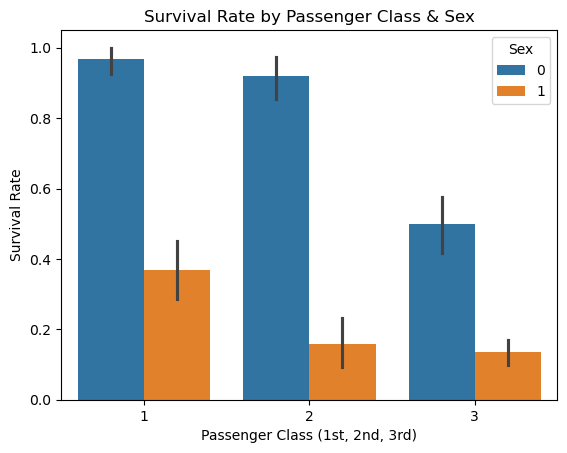

In [14]:
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex')
plt.title('Survival Rate by Passenger Class & Sex')
plt.xlabel('Passenger Class (1st, 2nd, 3rd)')
plt.ylabel('Survival Rate')
plt.show()

<Axes: xlabel='Age'>

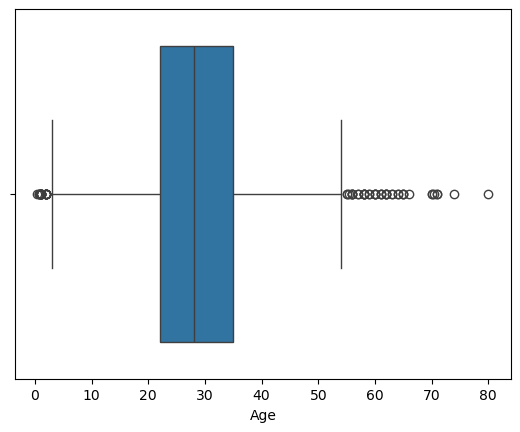

In [15]:
sns.boxplot(x=df["Age"])

<Axes: xlabel='Fare'>

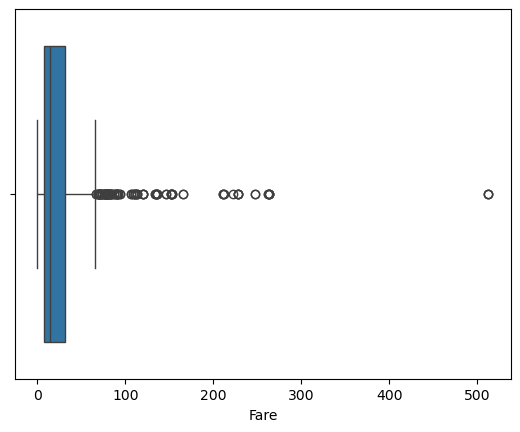

In [16]:
sns.boxplot(x=df["Fare"])

Text(0, 0.5, 'Number of peoples')

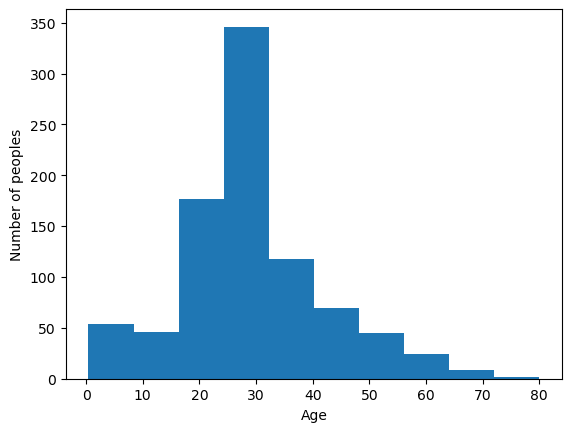

In [17]:
plt.hist(df['Age'])
plt.xlabel("Age")
plt.ylabel("Number of peoples")

## FEATURE SCALING

In [18]:
scaler = MinMaxScaler()

In [19]:
cols_to_scale = ["Age", "Fare"]
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

In [20]:
df.head(10)

,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,0,3,1,0.271174,1,0,A/5 21171,0.014151,2
1,1,1,0,0.472229,1,0,PC 17599,0.139136,0
2,1,3,0,0.321438,0,0,STON/O2. 3101282,0.015469,2
3,1,1,0,0.434531,1,0,113803,0.103644,2
4,0,3,1,0.434531,0,0,373450,0.015713,2
5,0,3,1,0.346569,0,0,330877,0.016510,1
6,0,1,1,0.673285,0,0,17463,0.101229,2
7,0,3,1,0.019854,3,1,349909,0.041136,2
8,1,3,0,0.334004,0,2,347742,0.021731,2
9,1,2,0,0.170646,1,0,237736,0.058694,0


#### Separating input and target

In [21]:
X = df.drop(columns=['Survived'])

y = df['Survived']

#### TRAIN TEST SPLIT

In [22]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [23]:
## Printing number of samples and features in our TRAINING dataset.
print("Number of samples in training dataset: ",X_train.shape[0])
print("Number of features in training dataset: ",X_train.shape[1])
print("Number of samples in testing dataset: ",X_test.shape[0])
print("Number of features in testing dataset: ",X_test.shape[1])

Number of samples in training dataset:  712
Number of features in training dataset:  8
Number of samples in testing dataset:  179
Number of features in testing dataset:  8


In [24]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
331,1,1,0.566474,0,0,113043,0.055628,2
733,2,1,0.283740,0,0,28425,0.025374,2
382,3,1,0.396833,0,0,STON/O 2. 3101293,0.015469,2
704,3,1,0.321438,1,0,350025,0.015330,2
813,3,0,0.070118,4,2,347082,0.061045,2
